In [30]:
import numpy as np
import pandas as pd

In [31]:
df = pd.read_csv(r"C:\Users\USER\Downloads\graduate_admission.csv")

In [32]:
x = df.iloc[:,:7]
y= df.iloc[:,-1]

In [33]:
from sklearn.model_selection import train_test_split
xtrain,xtest,ytrain,ytest = train_test_split(x,y,test_size=0.2,random_state=42)

In [34]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()

xtrain_scaled = scaler.fit_transform(xtrain)
xtest_scaled = scaler.transform(xtest)

In [35]:
import tensorflow
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense

In [46]:
model = Sequential()

model.add(Dense(7,activation='relu',input_dim=7))
model.add(Dense(7,activation='relu'))
model.add(Dense(1,activation='linear'))

C:\Users\USER\ml_env\Lib\site-packages\keras\src\layers\core\dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [47]:
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_7 (Dense)                 │ (None, 7)              │            56 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 7)              │            56 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │             8 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 120 (480.00 B)

 Trainable params: 120 (480.00 B)

 Non-trainable params: 0 (0.00 B)

In [48]:
model.compile(loss='mean_squared_error',optimizer='Adam')

In [53]:
history=model.fit(xtrain_scaled,ytrain,epochs=100,validation_split=0.2)

Epoch 1/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 299ms/step - loss: 0.0454 - val_loss: 0.0735
Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 268ms/step - loss: 0.0436 - val_loss: 0.0717
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 270ms/step - loss: 0.0419 - val_loss: 0.0701
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 232ms/step - loss: 0.0404 - val_loss: 0.0685
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 151ms/step - loss: 0.0390 - val_loss: 0.0671
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 190ms/step - loss: 0.0377 - val_loss: 0.0658
Epoch 7/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 318ms/step - loss: 0.0365 - val_loss: 0.0646
Epoch 8/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 267ms/step - loss: 0.0355 - val_loss: 0.0634
Epoch 9/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 220ms/step - loss: 0.0345 - val_loss: 0.0624
Epoch 10/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 214ms/step - loss: 0.0337 - val_loss: 0.0614
Epoch 11/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 215ms/step - loss: 0.0329 - val_loss: 0.0605
Epoch 12/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step - loss: 0.0

In [55]:
ypred=model.predict(xtest_scaled)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step


In [56]:
from sklearn.metrics import r2_score
r2_score(ytest,ypred)

-0.16646409382751104

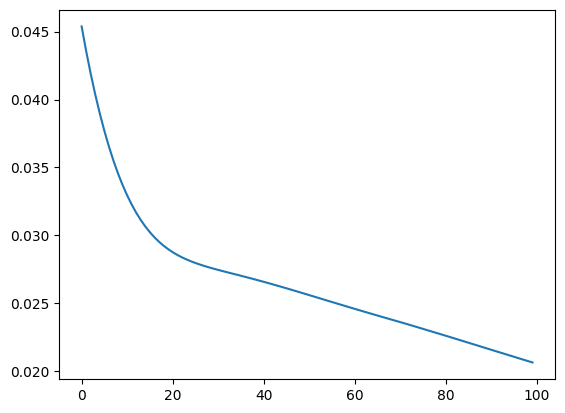

In [57]:
import matplotlib.pyplot as plt
plt.plot(history.history['loss'])